In [1]:
import numpy as np
devices={
    "Micra": {"D": 6.7, "L": 25.9}, # AV/AV2
    "AveirAR": {"D": 6.5, "L": 32.2}, # atrial Aveir DR device 
    "AveirVR": {"D": 6.5, "L": 38} # Atrial Aveir DR device + 10mm
}

for dev in ["AveirVR", "AveirAR" , "Micra"]:
    D = devices[dev]["D"]
    L = devices[dev]["L"]
    
    # Calculate original volume
    vol = np.pi * ((D / 2) ** 2) * L

    print('############################')
    print(f"Device: {dev}, volume: {vol/1000:.3f} cc")
    print(f"Original length: {L:1.2f}mm, original diameter: {D:1.2f} mm")

    # If we want to keep the same volume, calculate new diameter for each new length
    for length in [15, 20, 25, 30, 35, 40, 45]:
        new_R = np.sqrt(vol / (np.pi * length))*2 
        print(f"New length: {length} mm, new diameter: {new_R:1.2f} mm")


############################
Device: AveirVR, volume: 1.261 cc
Original length: 38.00mm, original diameter: 6.50 mm
New length: 15 mm, new diameter: 10.35 mm
New length: 20 mm, new diameter: 8.96 mm
New length: 25 mm, new diameter: 8.01 mm
New length: 30 mm, new diameter: 7.32 mm
New length: 35 mm, new diameter: 6.77 mm
New length: 40 mm, new diameter: 6.34 mm
New length: 45 mm, new diameter: 5.97 mm
############################
Device: AveirAR, volume: 1.068 cc
Original length: 32.20mm, original diameter: 6.50 mm
New length: 15 mm, new diameter: 9.52 mm
New length: 20 mm, new diameter: 8.25 mm
New length: 25 mm, new diameter: 7.38 mm
New length: 30 mm, new diameter: 6.73 mm
New length: 35 mm, new diameter: 6.23 mm
New length: 40 mm, new diameter: 5.83 mm
New length: 45 mm, new diameter: 5.50 mm
############################
Device: Micra, volume: 0.913 cc
Original length: 25.90mm, original diameter: 6.70 mm
New length: 15 mm, new diameter: 8.80 mm
New length: 20 mm, new diameter: 7.62 

In [15]:
# Intercept             4.168    0.863   4.827 0.000  2.475  5.860
# C(device)[T.AveirVR]  0.066    0.006  11.626 0.000  0.055  0.077
# C(device)[T.Micra]   -0.071    0.006 -12.555 0.000 -0.083 -0.060
# C(length)[T.20]       0.657    0.009  75.618 0.000  0.640  0.674
# C(length)[T.25]       1.238    0.009 142.613 0.000  1.221  1.255
# C(length)[T.30]       1.872    0.009 215.621 0.000  1.855  1.889
# C(length)[T.35]       2.585    0.009 297.680 0.000  2.568  2.602
# C(length)[T.40]       3.180    0.009 366.262 0.000  3.163  3.197
# C(length)[T.45]       3.709    0.009 427.158 0.000  3.692  3.726

A=[4.168, 0.066, -0.071, 0.657, 1.238, 1.872, 2.585, 3.180, 3.709]

import numpy as np 
print(np.diff(A)*10)
B=10*(np.array(A[3:])+A[0])

print(B)


[-41.02  -1.37   7.28   5.81   6.34   7.13   5.95   5.29]
[48.25 54.06 60.4  67.53 73.48 78.77]


In [2]:
19/3



6.333333333333333

case01_AveirVR_L38


/home/alee9/anaconda3/envs/py_vista/lib/python3.12/site-packages/pyvista/jupyter/notebook.py:36: UserWarning: Failed to use notebook backend: 

No module named 'trame'

Falling back to a static output.
  warnings.warn(


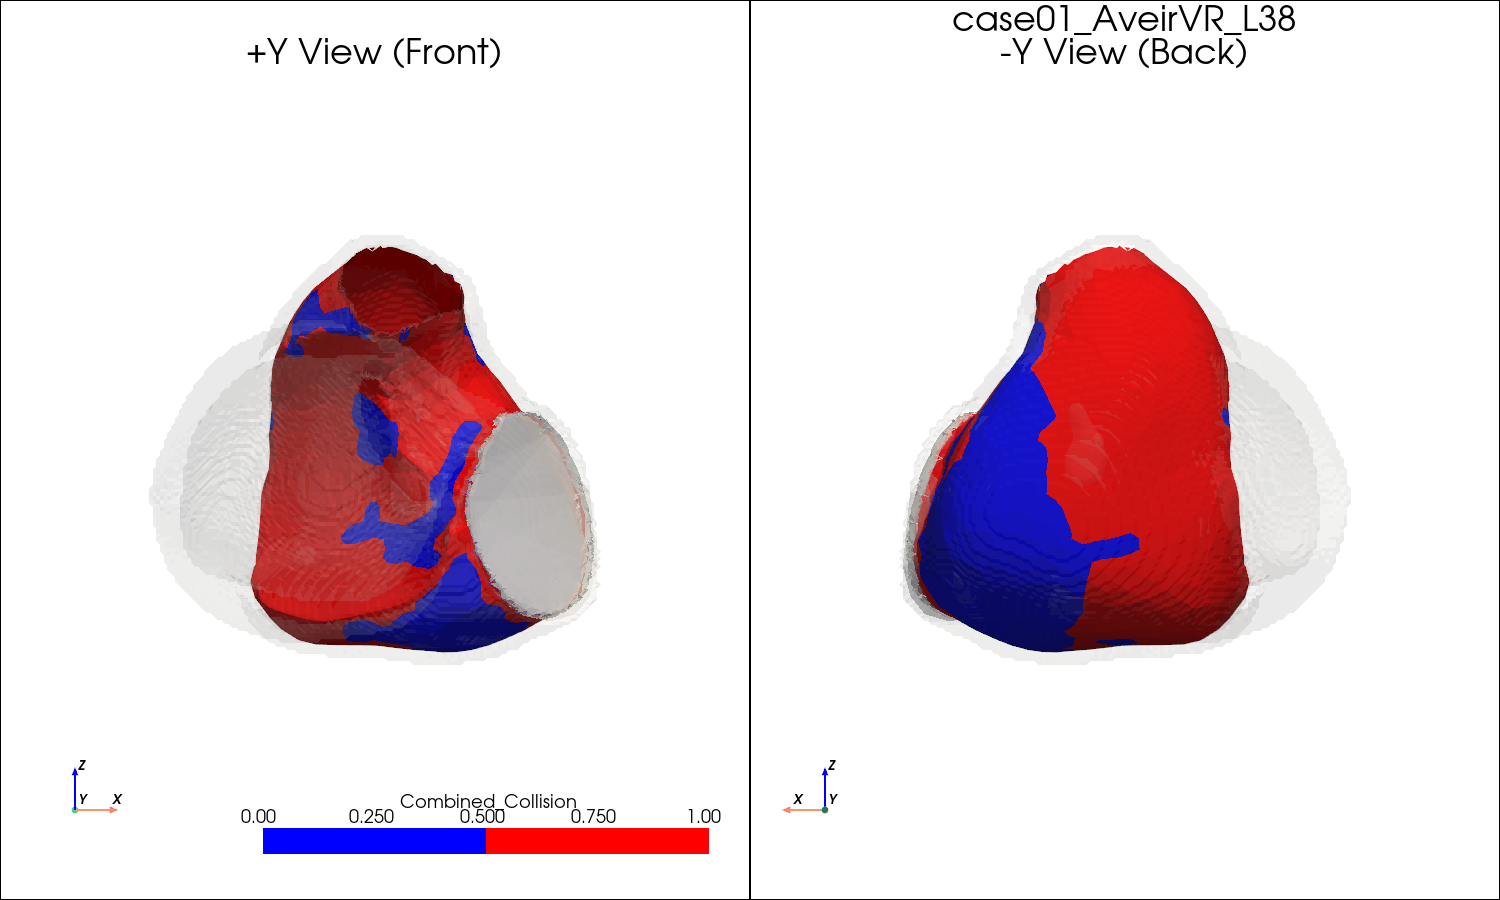

In [ ]:
# Visualise output data for FRONT AND BACK Y views of the RV mesh with the BiV mesh and PM mesh overlayed
import pyvista as pv
#import vtk_extras
import sys
sys.path.append('/data_slow/Dropbox/Work/Atria/code/python/vtk_extras')
import importlib
import screenshot_mesh_pdf
importlib.reload(screenshot_mesh_pdf)
import matplotlib.pyplot as plt
import matplotlib.backends.backend_pdf
from matplotlib.colors import ListedColormap

def plot_Y_views(mesh, field_name='Combined_Collision', mesh_opacity=1, mesh_colour='green', cmap=None):
    # XZ view
    plotter.subplot(0, 0)
    if field_name is not None and cmap is not None:
        plotter.add_mesh(mesh, scalars=field_name, cmap=cmap, preference='cell', opacity=mesh_opacity)
    else:
        plotter.add_mesh(mesh, color=mesh_colour, opacity=mesh_opacity)
    plotter.camera_position = 'xz'
    plotter.enable_parallel_projection()
    plotter.show_axes()    
    plotter.add_title("+Y View (Front)", font_size=14)

    # ZX view
    plotter.subplot(0, 1)
    if field_name is not None and cmap is not None:
        plotter.add_mesh(mesh, scalars=field_name, cmap=cmap, preference='cell', opacity=mesh_opacity)
    else:
        plotter.add_mesh(mesh, color=mesh_colour, opacity=mesh_opacity)
    plotter.camera_position = 'xz' #'zx'
    plotter.enable_parallel_projection()
    plotter.camera.azimuth= 180  # Rotate 180 degrees
    plotter.show_axes()
    plotter.add_title("-Y View (Back)", font_size=14)
 
for casenum in [1]: #range(1,14): #[1:13]:
    mainpath=f'/data_fast/Work/MS_HF_cohort/data/{casenum:02d}/2_motion/'
    images_outpath='/data_fast/Work/MS_HF_cohort/images/'
    bivfile=f'{mainpath}/BiV_masked_flip.vtk'
    pmfile=f'{mainpath}/PM_flip.vtk'
    try: 
        biv=pv.read(bivfile)
        pm=pv.read(pmfile)
    except FileNotFoundError:
        print('File not found: '+ bivfile + ' and/or PM_flip.vtk does not exist')
        #continue
    for device in ["AveirVR"]: #, "Nanostim"]: #'Micra']: 
        for length in [38]: #, 27, 32, 37, 42]: 
            #print(f'Checking output for case{casenum:02d}')

            simfile=f'{mainpath}/{device}/L{length}/RV_collision-all_times.vtk'
            try: 
                mesh=pv.read(simfile)
            except FileNotFoundError: 
                print('File not found: '+simfile)
                continue
            #cpos=plotter.show(return_cpos=True)   
            imgout=f'{images_outpath}/{device}/case{casenum:02d}_{device}_L{length}'
            title=f'case{casenum:02d}_{device}_L{length}'
            print(title)
            #points_data=None
            binary_cmap = ListedColormap(['blue', 'red'])
            field_name='Combined_Collision'
            mesh_opacity=1
            mesh_colour='green'
            cmap=binary_cmap

            # Create the plotter
            plotter = pv.Plotter(shape=(1, 2), off_screen=True, window_size=(1500, 900))

            # Add your meshes
            plot_Y_views(mesh, field_name='Combined_Collision', mesh_opacity=1, mesh_colour='green', cmap=binary_cmap)
            plot_Y_views(biv, field_name=None, mesh_opacity=0.1, mesh_colour='white')
            
            final_title = simfile if title is None else title
            plotter.add_text(final_title, position='upper_edge', font_size=14, color='black')
            
            # Render and capture the image directly
            #image = plotter.show(auto_close=True, return_img=True)
            #image = plotter.show(screenshot=imgout, auto_close=True)
            plotter.screenshot(imgout)
            plotter.show()
            #plotter.close()
            # Plot with matplotlib
            # fig, ax = plt.subplots()
            # fig.set_size_inches(18.5, 10.5)
            # ax.imshow(image)
            # ax.axis('off')  # optional: remove axis lines

            # # Set title
            # #if title is None:
            # #    fig.suptitle(simfile, fontsize=16)
            # #else:
            # #    fig.suptitle(title, fontsize=16)

            # # Save and show
            # fig.savefig(imgout, bbox_inches='tight')
            # plt.show()


In [83]:
import numpy as np
def define_structure(radius=1): 

    radius = radius+1
    diameter = 2 * radius + 1
    center = radius

    x, y, z = np.ogrid[:diameter, :diameter, :diameter]
    dist_squared = (x - center)**2 + (y - center)**2 + (z - center)**2

    # Strict spherical structuring element (Euclidean radius ≤ 1)
    structure = dist_squared <= radius**2
    structure=structure[1:-1,1:-1,1:-1]

    return structure

structure=define_structure(3)
print(structure)

#structure = np.ones((3, 3, 3))
#print(structure)


[[[False False False False False False False]
  [False False  True  True  True False False]
  [False  True  True  True  True  True False]
  [False  True  True  True  True  True False]
  [False  True  True  True  True  True False]
  [False False  True  True  True False False]
  [False False False False False False False]]

 [[False False  True  True  True False False]
  [False  True  True  True  True  True False]
  [ True  True  True  True  True  True  True]
  [ True  True  True  True  True  True  True]
  [ True  True  True  True  True  True  True]
  [False  True  True  True  True  True False]
  [False False  True  True  True False False]]

 [[False  True  True  True  True  True False]
  [ True  True  True  True  True  True  True]
  [ True  True  True  True  True  True  True]
  [ True  True  True  True  True  True  True]
  [ True  True  True  True  True  True  True]
  [ True  True  True  True  True  True  True]
  [False  True  True  True  True  True False]]

 [[False  True  True  True  